# La base enriquecida y su georreferenciación

Este capítulo muestra cómo se cruzó cada compraventa con el catastro y de dónde sale su
coordenada. Es la base que alimenta los capítulos 1 a 8 de esta versión del libro.

**Qué cambió frente a la versión anterior.** El registro del IGAC trae la matrícula
inmobiliaria *de la unidad* (el apartamento), y la capa de terrenos del catastro solo
traía la del *lote*. Por eso antes solo se ubicaba el 13 % de las ventas del IGAC. La
capa de predios del modelo LADM del Distrito (`predio`, capa 500) publica
`matricula_inmobiliaria` en el 99,8 % de las unidades en propiedad horizontal, y con
esa llave exacta se ubicó el 97,6 %.

La cadena de cruce:

```
venta IGAC (matrícula 040-XXXXXX)
  └─ matrícula → predio LADM (llave exacta; las que apuntan a varios predios se descartan)
        ├─ número predial nacional (30 dígitos) → estrato, condición PH/NPH, destinación
        ├─ predio matriz (21 dígitos + 9) → terreno LADM → coordenada del edificio
        └─ unidad de construcción → características: área, habitaciones, baños, piso, año
```

Las ventas de `avisos_registro` traen el número predial en su identificador y se ubican
directamente con él.

Archivos (en `datos/enriquecida/`):

| Archivo | Qué es |
|---|---|
| `tabla_consolidada.parquet` | Tabla A antes de enriquecer (IGAC, georreferenciadas, avisos, ofertas) |
| `tabla_a_enriquecida_anterior_14sep.parquet` | Tabla A enriquecida de la versión anterior |
| `tabla_a_enriquecida.parquet` | Tabla A enriquecida nueva, con el cruce por matrícula |
| `base_final.parquet` | Tabla A + observatorio (tabla B) con las marcas de calidad; es la misma que `datos/base_final_excel_es.csv` |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

R = "datos/enriquecida/"
consolidada = pd.read_parquet(R + "tabla_consolidada.parquet")
anterior = pd.read_parquet(R + "tabla_a_enriquecida_anterior_14sep.parquet")
nueva = pd.read_parquet(R + "tabla_a_enriquecida.parquet")
base = pd.read_parquet(R + "base_final.parquet")

# la oferta es precio pedido, no transado: no entra a la base
anterior = anterior[anterior.fuente != "oferta"]
nueva = nueva[nueva.fuente != "oferta"]
print(f"Tabla A anterior: {len(anterior):,}   Tabla A nueva: {len(nueva):,}   Base final: {len(base):,}")

Tabla A anterior: 46,325   Tabla A nueva: 46,325   Base final: 68,709


## Cobertura antes y ahora

In [2]:
def cobertura(d):
    return d.groupby("fuente").agg(
        filas=("id", "size"),
        con_codigo_predial=("CODIGO", lambda s: s.notna().sum()),
        con_coordenada=("lat", lambda s: s.notna().sum()),
        con_area_unidad=("area_unidad_principal", lambda s: s.notna().sum()),
        con_estrato=("estrato", lambda s: s.notna().sum()))

t = pd.concat({"antes (14-sep)": cobertura(anterior), "ahora": cobertura(nueva)}, axis=1)
t.loc["TOTAL"] = t.sum()
t

antes (14-sep)                                                                ahora                                                    \
                           filas con_codigo_predial con_coordenada con_area_unidad con_estrato  filas con_codigo_predial con_coordenada con_area_unidad   
fuente                                                                                                                                                    
avisos_registro              427                  0              0               0           0    427                427            421             146   
georreferenciadas           5351               4968           5130            4553        4968   5351               5320           5321            5299   
igac                       40547               5424           5438            5222        5423  40547              39624          39579           38597   
TOTAL                      46325              10392          10568            9775       10391  46325              45371          45321           44042   

                               
                  con_estrato  
fuente                         
avisos_registro            48  
georreferenciadas        5320  
igac                    39623  
TOTAL                   44991

In [3]:
pct = (pd.concat({"antes": anterior.groupby("fuente").lat.apply(lambda s: s.notna().mean()),
                  "ahora": nueva.groupby("fuente").lat.apply(lambda s: s.notna().mean())}, axis=1) * 100).round(1)
pct.rename(columns=lambda c: f"% con coordenada {c}")

,% con coordenada antes,% con coordenada ahora
fuente,,
avisos_registro,0.0,98.6
georreferenciadas,95.9,99.4
igac,13.4,97.6


El IGAC pasa de unas 5.400 ventas ubicadas a unas 39.600. Las georreferenciadas ya
estaban casi completas, y los avisos de registro pasan de ninguna a 421 de 427.

## Cómo se resolvió cada predio

In [4]:
pd.crosstab(nueva.fuente, nueva.origen_predio.fillna("sin resolver"), margins=True, margins_name="total")

origen_predio,matricula,numero_pre,sin resolver,terreno_ladm,unidad_2022,total
fuente,,,,,,
avisos_registro,0,427,0,0,0,427
georreferenciadas,5222,0,31,20,78,5351
igac,39515,0,923,14,95,40547
total,44737,427,954,34,173,46325


- `matricula`: llave exacta matrícula → predio LADM.
- `numero_pre`: número predial que trae el aviso de registro.
- `unidad_2022` / `terreno_ladm`: vecino más cercano (≤ 80 m) a la coordenada original,
  solo para las filas que tenían coordenada y no cruzaron por matrícula.
- `sin resolver`: matrículas que no existen en el LADM o que apuntan a varios predios.

In [5]:
pd.crosstab(nueva.fuente, nueva.condicion_predio.fillna("sin dato"))

condicion_predio,Condominio_Unidad_Predial,Informal,NPH,PH_Matriz,PH_Unidad_Predial,Via,sin dato
fuente,,,,,,,
avisos_registro,0,0,47,0,1,0,379
georreferenciadas,4,1,106,13,5193,3,31
igac,30,0,5332,56,34199,6,924


Antes, el IGAC solo llegaba a casas (`NPH`), porque cruzaba por la matrícula del lote.
Ahora la mayoría de sus ventas son apartamentos (`PH_Unidad_Predial`).

## De dónde salen las características

`unidad`: medidas en la unidad vendida. `edificio`: mediana de las viviendas del mismo
edificio, solo cuando la unidad no tiene características.

In [6]:
pd.crosstab(nueva.fuente, nueva.origen_caract.fillna("sin características"), margins=True, margins_name="total")

origen_caract,edificio,sin características,unidad,total
fuente,,,,
avisos_registro,5,281,141,427
georreferenciadas,41,52,5258,5351
igac,1137,1950,37460,40547
total,1183,2283,42859,46325


## Una muestra de registros cruzados

In [7]:
cols = ["id", "fuente", "matricula", "CODIGO", "origen_predio", "condicion_predio", "estrato",
        "lat", "lon", "area_unidad_principal", "total_habitaciones", "total_banios",
        "planta_ubicacion", "anio_construccion", "origen_caract", "precio", "anio"]
recien = nueva[(nueva.fuente == "igac") & nueva.lat.notna() & ~nueva.id.isin(anterior.loc[anterior.lat.notna(), "id"])]
print(f"Ventas del IGAC ubicadas por primera vez: {len(recien):,}")
recien[cols].sample(15, random_state=1)

Ventas del IGAC ubicadas por primera vez: 34,141


,id,fuente,matricula,CODIGO,origen_predio,condicion_predio,estrato,lat,lon,area_unidad_principal,total_habitaciones,total_banios,planta_ubicacion,anio_construccion,origen_caract,precio,anio
39785,igac:08001-040-629697-00007-00125-2022,igac,040-629697,080010117000000450001906020004,matricula,PH_Unidad_Predial,Medio_Bajo_3,10.992319,-74.849667,53.00,2.0,1.0,2.0,2020.0,unidad,150000000.0,2022
29076,igac:08001-040-609010-00005-00125-2021,igac,040-609010,080010117000000230002903080001,matricula,PH_Unidad_Predial,Medio_Bajo_3,10.993605,-74.845698,47.00,3.0,2.0,8.0,2019.0,unidad,122651008.0,2021
28328,igac:08001-040-607601-00005-00125-2022,igac,040-607601,080010103000002880006901090002,matricula,PH_Unidad_Predial,Medio_Bajo_3,11.024407,-74.805412,82.00,3.0,2.0,9.0,2020.0,unidad,233000000.0,2022
30646,igac:08001-040-612734-00004-00125-2021,igac,040-612734,080010117000000180005901100008,matricula,PH_Unidad_Predial,Medio_4,10.995484,-74.843104,73.00,3.0,2.0,10.0,2020.0,unidad,278712000.0,2021
28854,igac:08001-040-608690-00006-00125-2021,igac,040-608690,080010117000000440002908100003,matricula,PH_Unidad_Predial,Medio_Bajo_3,10.992603,-74.847948,52.00,3.0,2.0,10.0,2020.0,unidad,122651008.0,2021
28617,igac:08001-040-608400-00006-00125-2021,igac,040-608400,080010117000000440002906030001,matricula,PH_Unidad_Predial,Medio_Bajo_3,10.992603,-74.847948,51.00,3.0,2.0,3.0,2020.0,unidad,122651008.0,2021
13818,igac:08001-040-321702-00002-00125-2021,igac,040-321702,080010101000001120023901010001,matricula,PH_Unidad_Predial,Medio_Bajo_3,10.987972,-74.794730,12.00,0.0,0.0,1.0,1998.0,unidad,150000000.0,2021
25792,igac:08001-040-601894-00005-00125-2023,igac,040-601894,080010117000000440001910030004,matricula,PH_Unidad_Predial,Medio_Bajo_3,10.993573,-74.848023,51.00,3.0,2.0,3.0,2018.0,unidad,118503000.0,2023
11848,igac:08001-040-261978-00012-00125-2021,igac,040-261978,080010103000001420593901990004,matricula,PH_Unidad_Predial,Alto_6,11.006826,-74.809898,25.00,0.0,0.0,99.0,1986.0,unidad,29000000.0,2021
14871,igac:08001-040-376408-00010-00125-2022,igac,040-376408,080010103000009130001910020002,matricula,PH_Unidad_Predial,Medio_4,11.001187,-74.833347,82.00,3.0,2.0,2.0,2001.0,unidad,163000000.0,2022


In [8]:
def buscar(matricula):
    """Muestra cómo quedó cruzada una matrícula, p. ej. buscar("040-602684")."""
    return nueva.loc[nueva.matricula == matricula, cols].T

buscar(recien.matricula.iloc[0])

,5231
id,igac:08001-040-000412-00013-00125-2021
fuente,igac
matricula,040-412
CODIGO,080010103000000300017901020001
origen_predio,matricula
condicion_predio,PH_Unidad_Predial
estrato,Medio_Alto_5
lat,11.001076
lon,-74.808755
area_unidad_principal,253.0


## ¿Las coordenadas nuevas son correctas?

Unas 5.400 ventas del IGAC ya tenían coordenada por la vía anterior (matrícula del lote o
dirección). Se compara esa coordenada con la que da el cruce nuevo.

In [9]:
# El cruce conserva la coordenada original cuando ya existía, así que la del edificio se
# recalcula desde el terreno LADM (código predial → centroide), igual que en enriquecer_a.py
ter = pd.read_parquet(R + "terreno_ladm_coordenadas.parquet").set_index("name")
orig = consolidada.set_index("id")[["lat", "lon"]]
ig = nueva[(nueva.fuente == "igac") & (nueva.origen_predio == "matricula")].copy()
ig[["lat0", "lon0"]] = orig.reindex(ig.id).to_numpy()
cod = ig.CODIGO.astype("string")
for col in ("latitud", "longitud"):
    ig[col] = cod.map(ter[col])
    falta = ig[col].isna()
    ig.loc[falta, col] = (cod[falta].str[:21] + "900000000").map(ter[col])

ok = ig.lat0.notna() & ig.latitud.notna()
dist = np.hypot((ig.latitud - ig.lat0) * 111_000,
                (ig.longitud - ig.lon0) * 111_000 * np.cos(np.radians(11)))[ok]
pd.Series({"ventas con las dos coordenadas": ok.sum(),
           "distancia mediana (m)": round(dist.median(), 1),
           "percentil 90 (m)": round(dist.quantile(0.9), 1),
           "% a menos de 100 m": round((dist < 100).mean() * 100, 1),
           "% a más de 500 m": round((dist > 500).mean() * 100, 1)}).to_frame("valor")

,valor
ventas con las dos coordenadas,5306.0
distancia mediana (m),0.0
percentil 90 (m),1.7
% a menos de 100 m,98.9
% a más de 500 m,0.7


La coordenada nueva coincide con la anterior en prácticamente todos los casos. Es la del
**edificio**, no la del apartamento: todas las unidades de un edificio comparten el punto.

## Mapa: antes y ahora

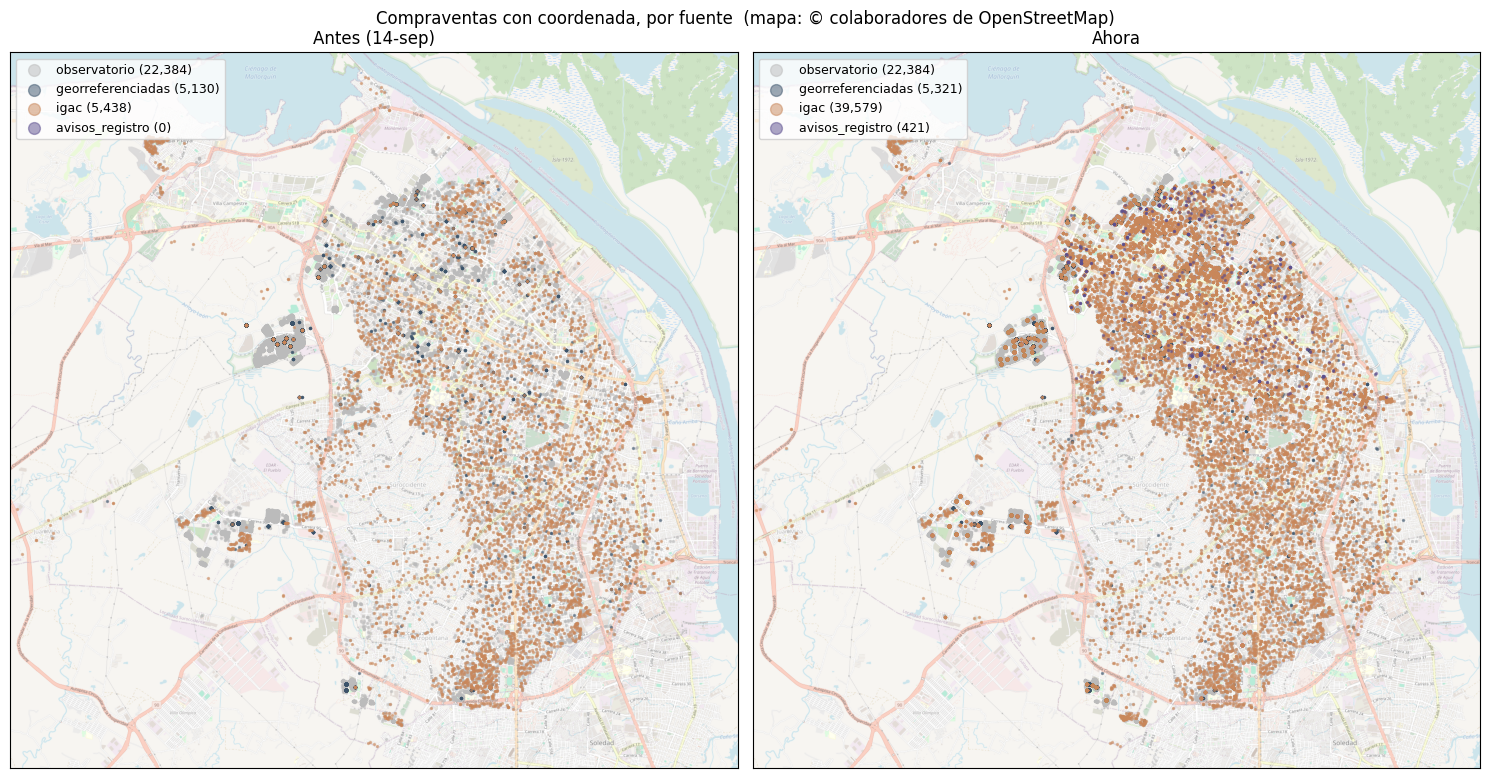

In [10]:
FONDO = np.asarray(Image.open("datos/mapa_base_barranquilla.png"))
# extensión del mosaico de teselas z=14 que arma el capítulo 5
import math
def _a_tesela(lon, lat, z):
    n = 2 ** z
    return (lon + 180) / 360 * n, (1 - math.asinh(math.tan(math.radians(lat))) / math.pi) / 2 * n
def _a_lonlat(x, y, z):
    n = 2 ** z
    return x / n * 360 - 180, math.degrees(math.atan(math.sinh(math.pi * (1 - 2 * y / n))))
EXT = (-74.90, -74.755, 10.91, 11.05)
x0, y0 = _a_tesela(EXT[0], EXT[3], 14); x1, y1 = _a_tesela(EXT[1], EXT[2], 14)
lo0, la1 = _a_lonlat(int(x0), int(y0), 14); lo1, la0 = _a_lonlat(int(x1) + 1, int(y1) + 1, 14)

fig, ejes = plt.subplots(1, 2, figsize=(15, 8))
for ax, (titulo, d) in zip(ejes, [("Antes (14-sep)", anterior), ("Ahora", nueva)]):
    ax.imshow(FONDO, extent=(lo0, lo1, la0, la1), alpha=0.6, zorder=0)
    for fuente, color in [("observatorio", "#BBBBBB"), ("georreferenciadas", "#3C546B"),
                          ("igac", "#C9875A"), ("avisos_registro", "#5B4E8E")]:
        p = d[d.fuente == fuente] if fuente != "observatorio" else base[base.fuente == "observatorio"]
        p = p[p.lat.notna()]
        ax.scatter(p.lon, p.lat, s=2, color=color, alpha=0.5, label=f"{fuente} ({len(p):,})", zorder=2)
    ax.set_xlim(EXT[0], EXT[1]); ax.set_ylim(EXT[2], EXT[3])
    ax.set_aspect(1 / np.cos(np.deg2rad(10.98))); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(titulo); ax.legend(loc="upper left", markerscale=6, fontsize=9)
plt.suptitle("Compraventas con coordenada, por fuente  (mapa: © colaboradores de OpenStreetMap)")
plt.tight_layout(); plt.show()

## Tasa de cruce por localidad

Si una zona cruza mucho mejor que otra, el modelo aprende sobre la primera y opina sobre la
segunda. Para el IGAC, la localidad sale de la base final, que la toma del predio.

In [11]:
ig_base = base[base.fuente == "igac"]
pd.DataFrame({
    "ventas IGAC": ig_base.groupby(ig_base.localidad.fillna("sin localidad")).size(),
    "aptas para modelar": ig_base[ig_base.apto_modelo].groupby(ig_base.localidad.fillna("sin localidad")).size(),
}).fillna(0).astype(int).sort_values("ventas IGAC", ascending=False)

,ventas IGAC,aptas para modelar
localidad,,
NORTE - CENTRO HISTORICO,11751,7755
SIN LOCALIDAD,8998,2694
RIOMAR,6659,3807
RURAL,4282,3322
SUROCCIDENTE,3813,3119
SURORIENTE,2101,1517
METROPOLITANA,1491,1075
sin localidad,1452,364


## Qué llega al modelo

In [12]:
pd.crosstab(base.fuente, base.apto_modelo.map({True: "apto_modelo", False: "excluido"}), margins=True, margins_name="total")

apto_modelo,apto_modelo,excluido,total
fuente,,,
avisos_registro,411,16,427
georreferenciadas,2325,3026,5351
igac,23653,16894,40547
observatorio,12836,9548,22384
total,39225,29484,68709


In [13]:
marcas = ["es_vis", "duplicado_en_b", "vivienda_en_sotano", "vivienda_sin_ambientes"]
base.groupby("fuente")[marcas].sum()

,es_vis,duplicado_en_b,vivienda_en_sotano,vivienda_sin_ambientes
fuente,,,,
avisos_registro,0,0,0,3
georreferenciadas,2248,3,8,12
igac,6794,5673,214,82
observatorio,4092,0,127,152


- `es_vis`: el precio es un tope legal de vivienda de interés social, no un precio de mercado.
- `duplicado_en_b`: la venta del IGAC ya está en el observatorio (mismo predio, año y precio).
  Se queda la del observatorio.

## Exportar para revisar en Excel

In [14]:
export = nueva[cols + ["barrio", "estrato_num", "destinacion_economica", "es_vis"]]
ruta = "datos/enriquecida/tabla_a_enriquecida_excel_es.csv"
export.assign(CODIGO="=\"" + export.CODIGO.astype("string") + "\"").to_csv(
    ruta, sep=";", decimal=",", index=False, encoding="utf-8-sig")
print(f"{len(export):,} filas → {ruta}")

46,325 filas → datos/enriquecida/tabla_a_enriquecida_excel_es.csv


## Limitaciones

- **1.833 matrículas apuntan a varios predios** en el LADM y se descartaron: adivinar
  cuál se vendió es peor que no cruzar.
- **La coordenada es la del edificio.** Sirve para ubicar, pero no distingue apartamentos
  del mismo edificio. Eso lo hacen el piso, el área y las demás características.
- **El avalúo cubre a menos de la mitad de la base nueva.** Sale de la capa de área
  construida de 2022, cuyos códigos no siempre coinciden con el número predial vigente.
  Por eso el filtro de "ventas registradas al avalúo" del capítulo 7 casi no se puede
  aplicar a los apartamentos nuevos del IGAC. En los que sí tienen avalúo, solo el 1,9 %
  está al avalúo, así que el riesgo es bajo.
- **Avisos de registro:** 421 de 427 tienen coordenada, pero solo 48 tienen estrato,
  porque su número predial es del corte de 2022.